In [46]:
# Cell 1: Import core data-science libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')
print('Core libraries imported.')

Core libraries imported.


In [47]:
# Cell 2: Import scikit-learn preprocessing, regressors, and evaluation metrics
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print('Scikit-learn modules imported.')

Scikit-learn modules imported.


In [48]:
# Cell 3: Load the UCI Air Quality CSV (European format) and display first 5 rows
df = pd.read_csv('AirQualityUCI.csv', sep=';', decimal=',')
df.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


In [49]:
# Cell 4: Check and print the initial shape and column names
print(f'Initial shape: {df.shape}')
print(f'Columns: {list(df.columns)}')

Initial shape: (9471, 17)
Columns: ['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Unnamed: 15', 'Unnamed: 16']


In [50]:
# Cell 5: Drop the completely empty trailing columns (Unnamed: 15, Unnamed: 16)
df.drop(columns=['Unnamed: 15', 'Unnamed: 16'], inplace=True)
print(f'Shape after dropping empty columns: {df.shape}')
print(f'Remaining columns: {list(df.columns)}')

Shape after dropping empty columns: (9471, 15)
Remaining columns: ['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']


In [51]:
# Cell 6: Drop all completely empty trailing rows and print the new shape
df.dropna(how='all', inplace=True)
df.reset_index(drop=True, inplace=True)
print(f'Shape after dropping empty rows: {df.shape}')

Shape after dropping empty rows: (9357, 15)


In [52]:
# Cell 7: Replace all -200 sentinel error values with NaN
df.replace(-200, np.nan, inplace=True)
print(f'Total NaN values after sentinel replacement: {df.isna().sum().sum()}')
print(df.isna().sum())

Total NaN values after sentinel replacement: 16701
Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64


In [53]:
# Cell 8: Combine Date and Time into a parsed Datetime index, drop originals, sort chronologically
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H.%M.%S')
df.set_index('Datetime', inplace=True)
df.drop(columns=['Date', 'Time'], inplace=True)
df.sort_index(inplace=True)
print(f'Datetime index range: {df.index.min()} to {df.index.max()}')
df.head()

Datetime index range: 2004-03-10 18:00:00 to 2005-04-04 14:00:00


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
Datetime,,,,,,,,,,,,,
2004-03-10 18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
2004-03-10 19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2004-03-10 20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
2004-03-10 21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
2004-03-10 22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


In [54]:
# Cell 9: Impute missing values using forward-fill followed by backward-fill
df.ffill(inplace=True)
df.bfill(inplace=True)
print(f'Remaining NaN values after imputation: {df.isna().sum().sum()}')

Remaining NaN values after imputation: 0


In [55]:
# Cell 10: Define target y as C6H6(GT) and feature matrix X with selected sensor columns
target_col = 'C6H6(GT)'
feature_cols = ['PT08.S1(CO)', 'PT08.S2(NMHC)', 'NOx(GT)', 'NO2(GT)', 'T', 'RH']
y = df[target_col].copy()
X = df[feature_cols].copy()
print(f'Feature matrix X shape: {X.shape}')
print(f'Target vector y shape: {y.shape}')

Feature matrix X shape: (9357, 6)
Target vector y shape: (9357,)


In [56]:
# Cell 11: Compute summary statistics (mean, std, min, max) for X and y
print('=== Feature Summary Statistics ===')
print(X.describe().loc[['mean', 'std', 'min', 'max']].round(3))
print(f'\n=== Target Summary Statistics ===')
print(y.describe().loc[['mean', 'std', 'min', 'max']].round(3))

=== Feature Summary Statistics ===
      PT08.S1(CO)  PT08.S2(NMHC)   NOx(GT)  NO2(GT)       T      RH
mean     1102.730        942.548   240.731  109.415  18.317  48.817
std       219.588        269.581   206.618   47.222   8.822  17.354
min       647.000        383.000     2.000    2.000  -1.900   9.200
max      2040.000       2214.000  1479.000  340.000  44.600  88.700

=== Target Summary Statistics ===
mean    10.190
std      7.566
min      0.100
max     63.700
Name: C6H6(GT), dtype: float64


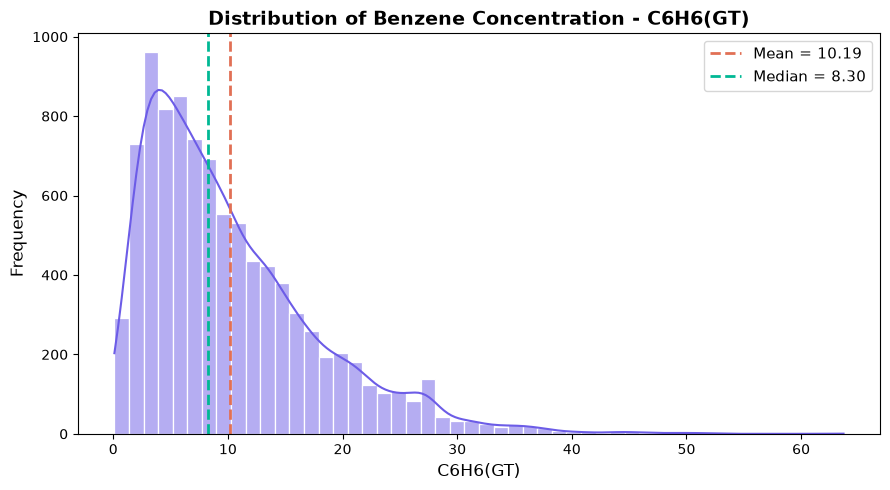

In [57]:
# Cell 12: Plot a histogram with KDE for the target variable C6H6(GT)
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(y, kde=True, bins=50, color='#6C5CE7', edgecolor='white', ax=ax)
ax.set_title('Distribution of Benzene Concentration - C6H6(GT)', fontsize=14, fontweight='bold')
ax.set_xlabel('C6H6(GT)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.axvline(y.mean(), color='#E17055', ls='--', lw=2, label=f'Mean = {y.mean():.2f}')
ax.axvline(y.median(), color='#00B894', ls='--', lw=2, label=f'Median = {y.median():.2f}')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

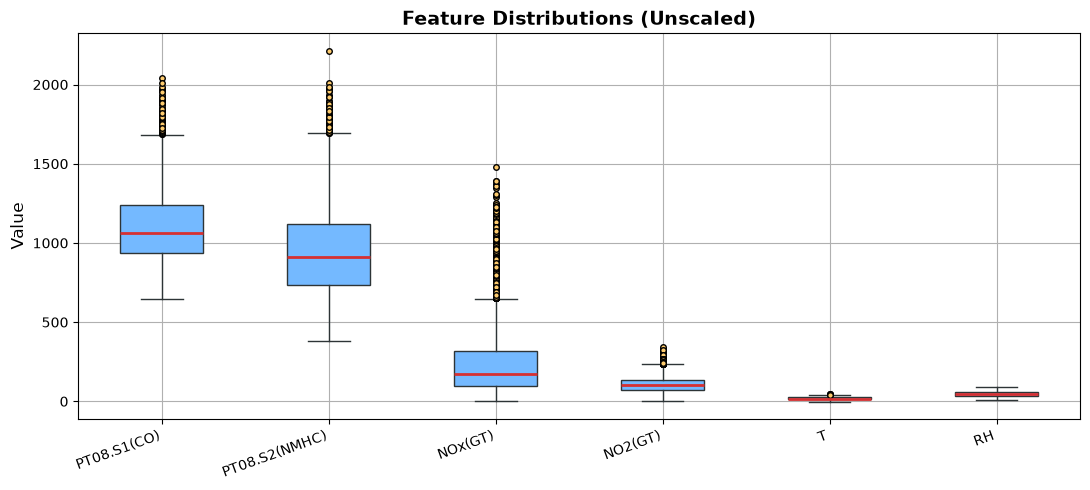

In [58]:
# Cell 13: Plot boxplots for the unscaled feature matrix to visualize dispersion
fig, ax = plt.subplots(figsize=(11, 5))
X.boxplot(ax=ax, patch_artist=True,
          boxprops=dict(facecolor='#74B9FF', edgecolor='#2D3436'),
          medianprops=dict(color='#D63031', linewidth=2),
          whiskerprops=dict(color='#2D3436'),
          capprops=dict(color='#2D3436'),
          flierprops=dict(marker='o', markerfacecolor='#FDCB6E', markersize=4))
ax.set_title('Feature Distributions (Unscaled)', fontsize=14, fontweight='bold')
ax.set_ylabel('Value', fontsize=12)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

In [59]:
# Cell 14: Compute and print the Pearson correlation matrix
corr_data = X.copy()
corr_data[target_col] = y
corr_matrix = corr_data.corr(method='pearson').round(3)
print('=== Pearson Correlation Matrix ===')
print(corr_matrix)

=== Pearson Correlation Matrix ===
               PT08.S1(CO)  PT08.S2(NMHC)  NOx(GT)  NO2(GT)      T     RH  \
PT08.S1(CO)          1.000          0.896    0.645    0.581  0.037  0.120   
PT08.S2(NMHC)        0.896          1.000    0.627    0.566  0.231 -0.082   
NOx(GT)              0.645          0.627    1.000    0.764 -0.244  0.184   
NO2(GT)              0.581          0.566    0.764    1.000 -0.195 -0.099   
T                    0.037          0.231   -0.244   -0.195  1.000 -0.571   
RH                   0.120         -0.082    0.184   -0.099 -0.571  1.000   
C6H6(GT)             0.886          0.982    0.638    0.537  0.190 -0.055   

               C6H6(GT)  
PT08.S1(CO)       0.886  
PT08.S2(NMHC)     0.982  
NOx(GT)           0.638  
NO2(GT)           0.537  
T                 0.190  
RH               -0.055  
C6H6(GT)          1.000  


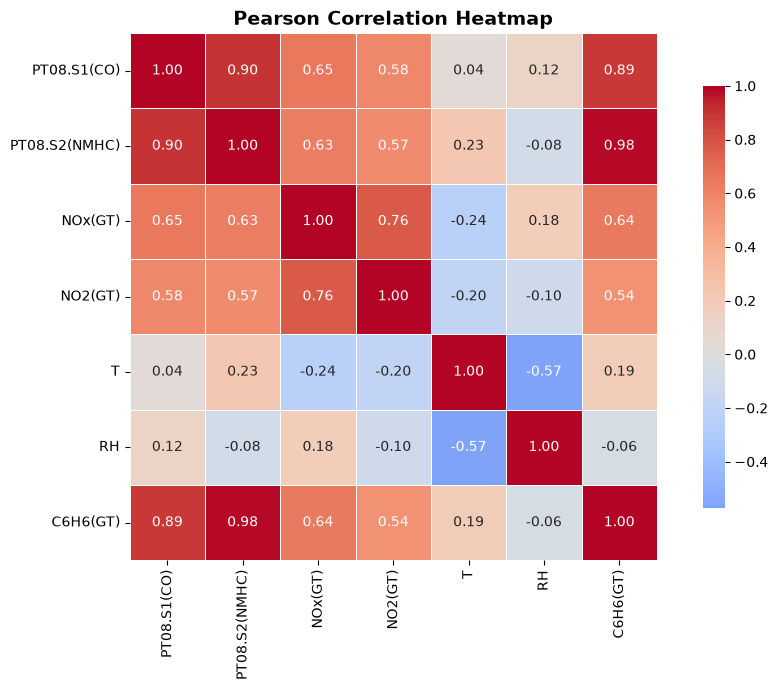

In [60]:
# Cell 15: Plot the annotated Seaborn correlation heatmap
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, square=True, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Pearson Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

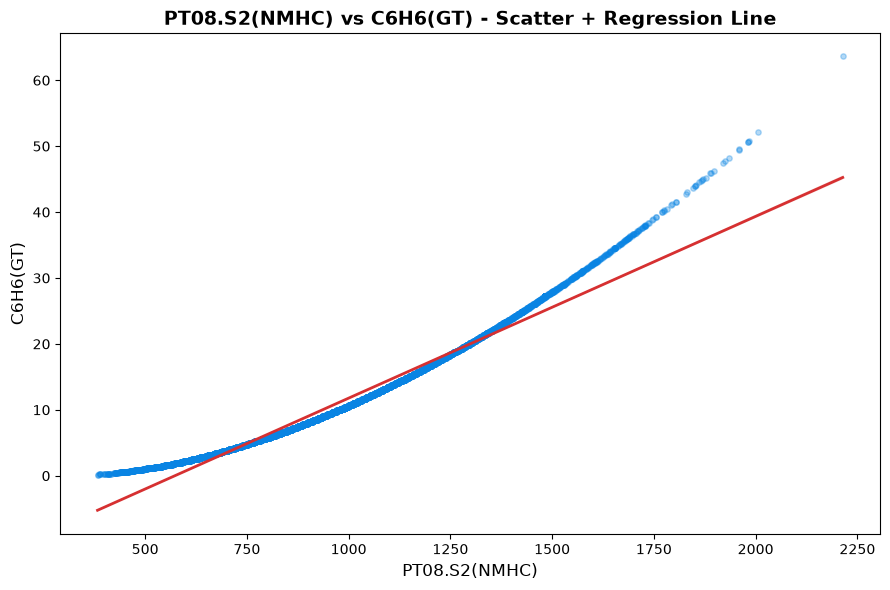

In [61]:
# Cell 16: Regplot showing PT08.S2(NMHC) vs C6H6(GT) with linear regression line
fig, ax = plt.subplots(figsize=(9, 6))
sns.regplot(x=X['PT08.S2(NMHC)'], y=y,
            scatter_kws={'alpha': 0.3, 's': 15, 'color': '#0984E3'},
            line_kws={'color': '#D63031', 'linewidth': 2}, ax=ax)
ax.set_title('PT08.S2(NMHC) vs C6H6(GT) - Scatter + Regression Line', fontsize=14, fontweight='bold')
ax.set_xlabel('PT08.S2(NMHC)', fontsize=12)
ax.set_ylabel('C6H6(GT)', fontsize=12)
plt.tight_layout()
plt.show()

In [62]:
# Cell 17: Perform 80/20 train-test split BEFORE scaling (leakage prevention)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f'X_train: {X_train.shape}  |  X_test: {X_test.shape}')
print(f'y_train: {y_train.shape}  |  y_test: {y_test.shape}')

X_train: (7485, 6)  |  X_test: (1872, 6)
y_train: (7485,)  |  y_test: (1872,)


In [63]:
# Cell 18: Calculate IQR lower and upper bounds strictly on X_train
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print('IQR Lower Bounds:')
print(lower_bound.round(2))
print('\nIQR Upper Bounds:')
print(upper_bound.round(2))

IQR Lower Bounds:
PT08.S1(CO)      491.50
PT08.S2(NMHC)    155.50
NOx(GT)         -232.00
NO2(GT)          -23.00
T                 -6.55
RH                -3.75
dtype: float64

IQR Upper Bounds:
PT08.S1(CO)      1687.50
PT08.S2(NMHC)    1695.50
NOx(GT)           648.00
NO2(GT)           233.00
T                  42.65
RH                101.45
dtype: float64


In [64]:
# Cell 19: Clip (Winsorize) outliers in both X_train and X_test using train-derived bounds
X_train = X_train.clip(lower=lower_bound, upper=upper_bound, axis=1)
X_test = X_test.clip(lower=lower_bound, upper=upper_bound, axis=1)
print('Outlier clipping applied using training-set IQR bounds.')

Outlier clipping applied using training-set IQR bounds.


In [65]:
# Cell 20: Fit StandardScaler on X_train, transform X_train and X_test
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(f'X_train_scaled mean (per feature): {X_train_scaled.mean(axis=0).round(6)}')
print(f'X_train_scaled std  (per feature): {X_train_scaled.std(axis=0).round(4)}')

X_train_scaled mean (per feature): [-0. -0.  0.  0. -0. -0.]
X_train_scaled std  (per feature): [1. 1. 1. 1. 1. 1.]


In [66]:
# Helper: Evaluation function for all Unit 3 regression metrics
def evaluate_model(name, y_true, y_pred, n_features):
    n = len(y_true)
    k = n_features
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    adj_r2 = 1 - ((1 - r2) * (n - 1)) / (n - k - 1)
    return {'Model': name, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2, 'Adj_R2': adj_r2}

results = []
n_feat = X_train_scaled.shape[1]
print(f'Number of features (k): {n_feat}')

Number of features (k): 6


In [67]:
# Model 1A: Fit Multiple Linear Regression and predict on test data
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)
print('Linear Regression fitted and predictions generated.')

Linear Regression fitted and predictions generated.


In [68]:
# Model 1B: Print MAE, MSE, RMSE, R-Squared, and Adjusted R-Squared for Linear Regression
res_lr = evaluate_model('Linear Regression', y_test, y_pred_lr, n_feat)
results.append(res_lr)
print('=== Linear Regression Metrics ===')
for k, v in res_lr.items():
    if k != 'Model':
        print(f'  {k:>8s}: {v:.4f}')

=== Linear Regression Metrics ===
       MAE: 1.0103
       MSE: 2.5414
      RMSE: 1.5942
        R2: 0.9566
    Adj_R2: 0.9564


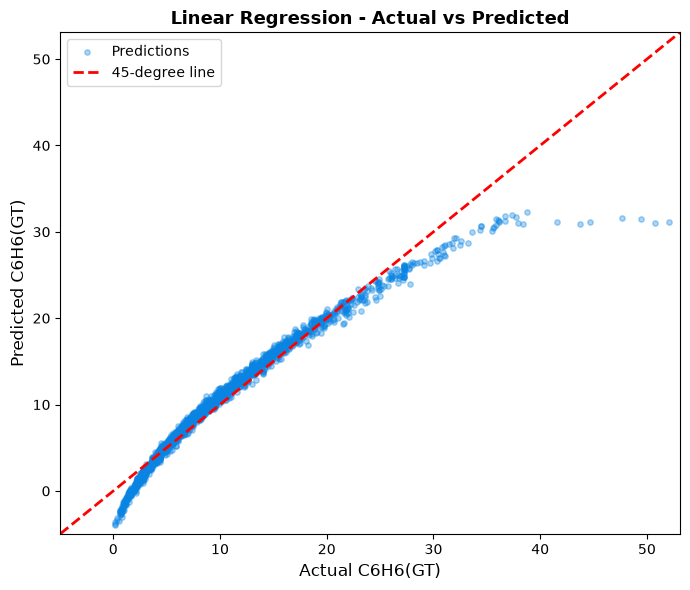

In [69]:
# Model 1C: Scatter plot of True vs Predicted values with 45-degree reference line
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred_lr, alpha=0.35, s=15, color='#0984E3', label='Predictions')
lims = [min(y_test.min(), y_pred_lr.min()) - 1, max(y_test.max(), y_pred_lr.max()) + 1]
ax.plot(lims, lims, '--', color='red', lw=2, label='45-degree line')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Actual C6H6(GT)', fontsize=12)
ax.set_ylabel('Predicted C6H6(GT)', fontsize=12)
ax.set_title('Linear Regression - Actual vs Predicted', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

In [70]:
# Model 2A: Fit Ridge Regression (alpha=1.0) and predict on test data
ridge = Ridge(alpha=1.0, random_state=42)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_test_scaled)
print('Ridge Regression fitted and predictions generated.')

Ridge Regression fitted and predictions generated.


In [71]:
# Model 2B: Print MAE, MSE, RMSE, R-Squared, and Adjusted R-Squared for Ridge
res_ridge = evaluate_model('Ridge Regression', y_test, y_pred_ridge, n_feat)
results.append(res_ridge)
print('=== Ridge Regression Metrics ===')
for k, v in res_ridge.items():
    if k != 'Model':
        print(f'  {k:>8s}: {v:.4f}')

=== Ridge Regression Metrics ===
       MAE: 1.0101
       MSE: 2.5416
      RMSE: 1.5942
        R2: 0.9566
    Adj_R2: 0.9564


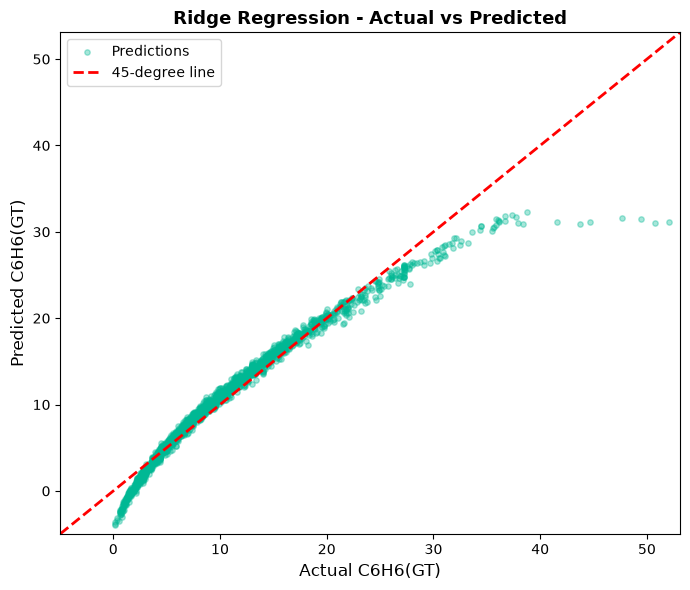

In [72]:
# Model 2C: Scatter plot of True vs Predicted values with 45-degree reference line
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred_ridge, alpha=0.35, s=15, color='#00B894', label='Predictions')
lims = [min(y_test.min(), y_pred_ridge.min()) - 1, max(y_test.max(), y_pred_ridge.max()) + 1]
ax.plot(lims, lims, '--', color='red', lw=2, label='45-degree line')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Actual C6H6(GT)', fontsize=12)
ax.set_ylabel('Predicted C6H6(GT)', fontsize=12)
ax.set_title('Ridge Regression - Actual vs Predicted', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

In [73]:
# Model 3A: Fit Lasso Regression (alpha=0.1) and predict on test data
lasso = Lasso(alpha=0.1, random_state=42, max_iter=10000)
lasso.fit(X_train_scaled, y_train)
y_pred_lasso = lasso.predict(X_test_scaled)
print('Lasso Regression fitted and predictions generated.')

Lasso Regression fitted and predictions generated.


In [74]:
# Model 3B: Print MAE, MSE, RMSE, R-Squared, and Adjusted R-Squared for Lasso
res_lasso = evaluate_model('Lasso Regression', y_test, y_pred_lasso, n_feat)
results.append(res_lasso)
print('=== Lasso Regression Metrics ===')
for k, v in res_lasso.items():
    if k != 'Model':
        print(f'  {k:>8s}: {v:.4f}')

=== Lasso Regression Metrics ===
       MAE: 1.0278
       MSE: 2.6766
      RMSE: 1.6360
        R2: 0.9543
    Adj_R2: 0.9541


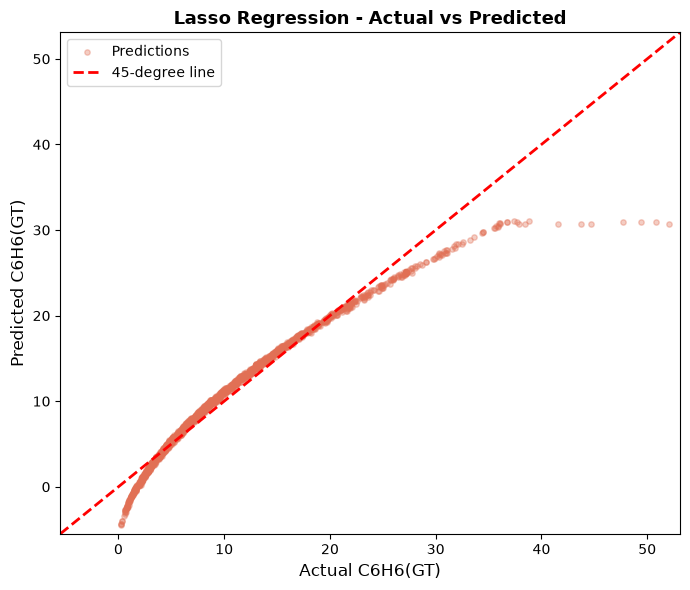

In [75]:
# Model 3C: Scatter plot of True vs Predicted values with 45-degree reference line
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred_lasso, alpha=0.35, s=15, color='#E17055', label='Predictions')
lims = [min(y_test.min(), y_pred_lasso.min()) - 1, max(y_test.max(), y_pred_lasso.max()) + 1]
ax.plot(lims, lims, '--', color='red', lw=2, label='45-degree line')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Actual C6H6(GT)', fontsize=12)
ax.set_ylabel('Predicted C6H6(GT)', fontsize=12)
ax.set_title('Lasso Regression - Actual vs Predicted', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

In [76]:
# Model 4A: Fit Decision Tree Regressor (max_depth=10) and predict on test data
dt = DecisionTreeRegressor(max_depth=10, random_state=42)
dt.fit(X_train_scaled, y_train)
y_pred_dt = dt.predict(X_test_scaled)
print('Decision Tree Regressor fitted and predictions generated.')

Decision Tree Regressor fitted and predictions generated.


In [77]:
# Model 4B: Print MAE, MSE, RMSE, R-Squared, and Adjusted R-Squared for Decision Tree
res_dt = evaluate_model('Decision Tree', y_test, y_pred_dt, n_feat)
results.append(res_dt)
print('=== Decision Tree Regressor Metrics ===')
for k, v in res_dt.items():
    if k != 'Model':
        print(f'  {k:>8s}: {v:.4f}')

=== Decision Tree Regressor Metrics ===
       MAE: 0.0268
       MSE: 0.0878
      RMSE: 0.2962
        R2: 0.9985
    Adj_R2: 0.9985


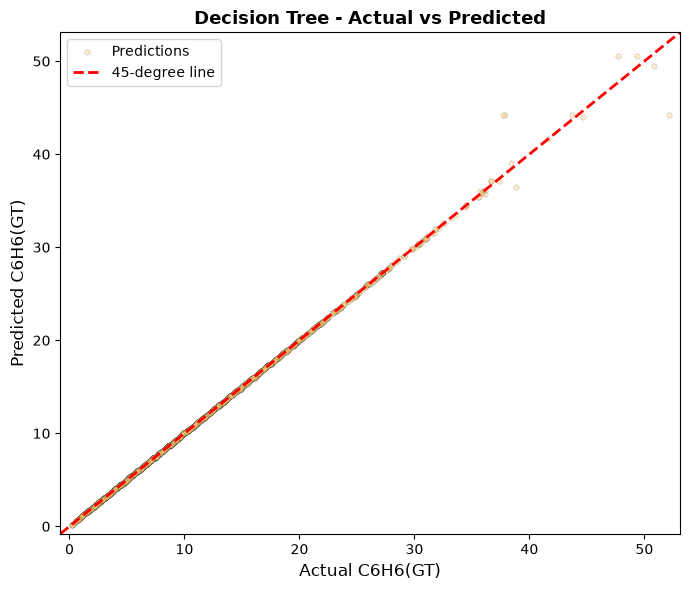

In [78]:
# Model 4C: Scatter plot of True vs Predicted values with 45-degree reference line
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred_dt, alpha=0.35, s=15, color='#FDCB6E', edgecolors='#2D3436', linewidths=0.3, label='Predictions')
lims = [min(y_test.min(), y_pred_dt.min()) - 1, max(y_test.max(), y_pred_dt.max()) + 1]
ax.plot(lims, lims, '--', color='red', lw=2, label='45-degree line')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Actual C6H6(GT)', fontsize=12)
ax.set_ylabel('Predicted C6H6(GT)', fontsize=12)
ax.set_title('Decision Tree - Actual vs Predicted', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

In [79]:
# Model 5A: Fit Random Forest Regressor (200 trees, max_depth=15) and predict on test data
rf = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train_scaled, y_train)
y_pred_rf = rf.predict(X_test_scaled)
print('Random Forest Regressor fitted and predictions generated.')

Random Forest Regressor fitted and predictions generated.


In [80]:
# Model 5B: Print MAE, MSE, RMSE, R-Squared, and Adjusted R-Squared for Random Forest
res_rf = evaluate_model('Random Forest', y_test, y_pred_rf, n_feat)
results.append(res_rf)
print('=== Random Forest Regressor Metrics ===')
for k, v in res_rf.items():
    if k != 'Model':
        print(f'  {k:>8s}: {v:.4f}')

=== Random Forest Regressor Metrics ===
       MAE: 0.0341
       MSE: 0.1250
      RMSE: 0.3535
        R2: 0.9979
    Adj_R2: 0.9979


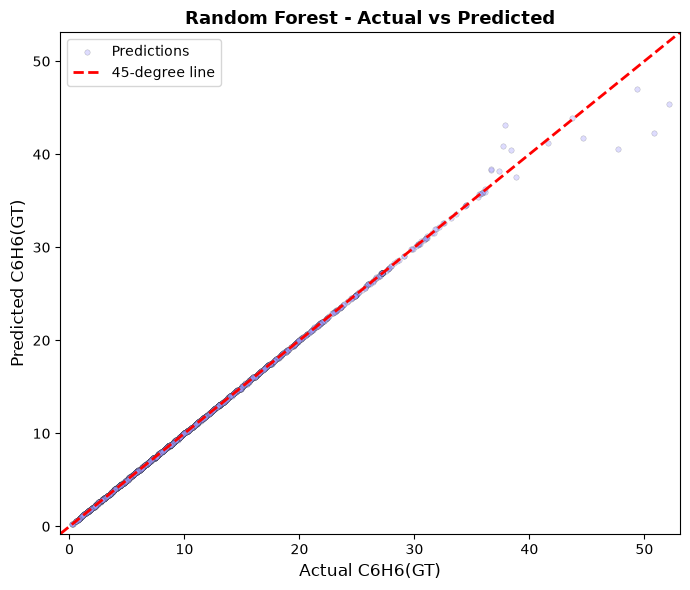

In [81]:
# Model 5C: Scatter plot of True vs Predicted values with 45-degree reference line
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred_rf, alpha=0.35, s=15, color='#A29BFE', edgecolors='#2D3436', linewidths=0.3, label='Predictions')
lims = [min(y_test.min(), y_pred_rf.min()) - 1, max(y_test.max(), y_pred_rf.max()) + 1]
ax.plot(lims, lims, '--', color='red', lw=2, label='45-degree line')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Actual C6H6(GT)', fontsize=12)
ax.set_ylabel('Predicted C6H6(GT)', fontsize=12)
ax.set_title('Random Forest - Actual vs Predicted', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

In [82]:
# Model 6A: Fit Support Vector Regressor (RBF kernel, C=100) and predict on test data
svr = SVR(kernel='rbf', C=100, epsilon=0.1)
svr.fit(X_train_scaled, y_train)
y_pred_svr = svr.predict(X_test_scaled)
print('SVR fitted and predictions generated.')

SVR fitted and predictions generated.


In [83]:
# Model 6B: Print MAE, MSE, RMSE, R-Squared, and Adjusted R-Squared for SVR
res_svr = evaluate_model('SVR', y_test, y_pred_svr, n_feat)
results.append(res_svr)
print('=== SVR Metrics ===')
for k, v in res_svr.items():
    if k != 'Model':
        print(f'  {k:>8s}: {v:.4f}')

=== SVR Metrics ===
       MAE: 0.0862
       MSE: 0.3452
      RMSE: 0.5875
        R2: 0.9941
    Adj_R2: 0.9941


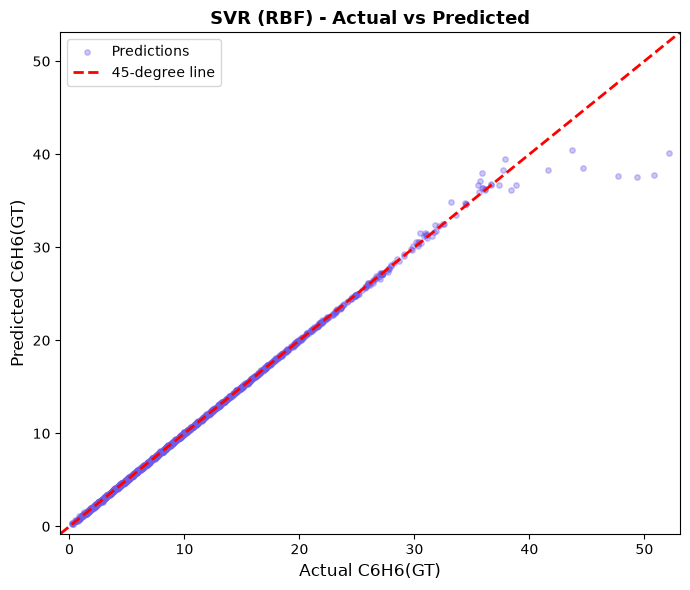

In [84]:
# Model 6C: Scatter plot of True vs Predicted values with 45-degree reference line
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred_svr, alpha=0.35, s=15, color='#6C5CE7', label='Predictions')
lims = [min(y_test.min(), y_pred_svr.min()) - 1, max(y_test.max(), y_pred_svr.max()) + 1]
ax.plot(lims, lims, '--', color='red', lw=2, label='45-degree line')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Actual C6H6(GT)', fontsize=12)
ax.set_ylabel('Predicted C6H6(GT)', fontsize=12)
ax.set_title('SVR (RBF) - Actual vs Predicted', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

In [85]:
# Cell 39: Compile all 6 model metrics into a clean, presentation-ready DataFrame sorted by R2
comparison = pd.DataFrame(results)
comparison = comparison.sort_values(by='R2', ascending=False).reset_index(drop=True)
comparison.index = comparison.index + 1
comparison.index.name = 'Rank'
styled = comparison.round(4).to_string()
print('=' * 75)
print('  MODEL COMPARISON — Sorted by R-Squared (Descending)')
print('=' * 75)
print(styled)
print('=' * 75)
print(f'\n  Champion: {comparison.iloc[0]["Model"]}  |  R2 = {comparison.iloc[0]["R2"]:.4f}  |  RMSE = {comparison.iloc[0]["RMSE"]:.4f}')


  MODEL COMPARISON — Sorted by R-Squared (Descending)
                  Model     MAE     MSE    RMSE      R2  Adj_R2
Rank                                                           
1         Decision Tree  0.0268  0.0878  0.2962  0.9985  0.9985
2         Random Forest  0.0341  0.1250  0.3535  0.9979  0.9979
3                   SVR  0.0862  0.3452  0.5875  0.9941  0.9941
4     Linear Regression  1.0103  2.5414  1.5942  0.9566  0.9564
5      Ridge Regression  1.0101  2.5416  1.5942  0.9566  0.9564
6      Lasso Regression  1.0278  2.6766  1.6360  0.9543  0.9541

  Champion: Decision Tree  |  R2 = 0.9985  |  RMSE = 0.2962


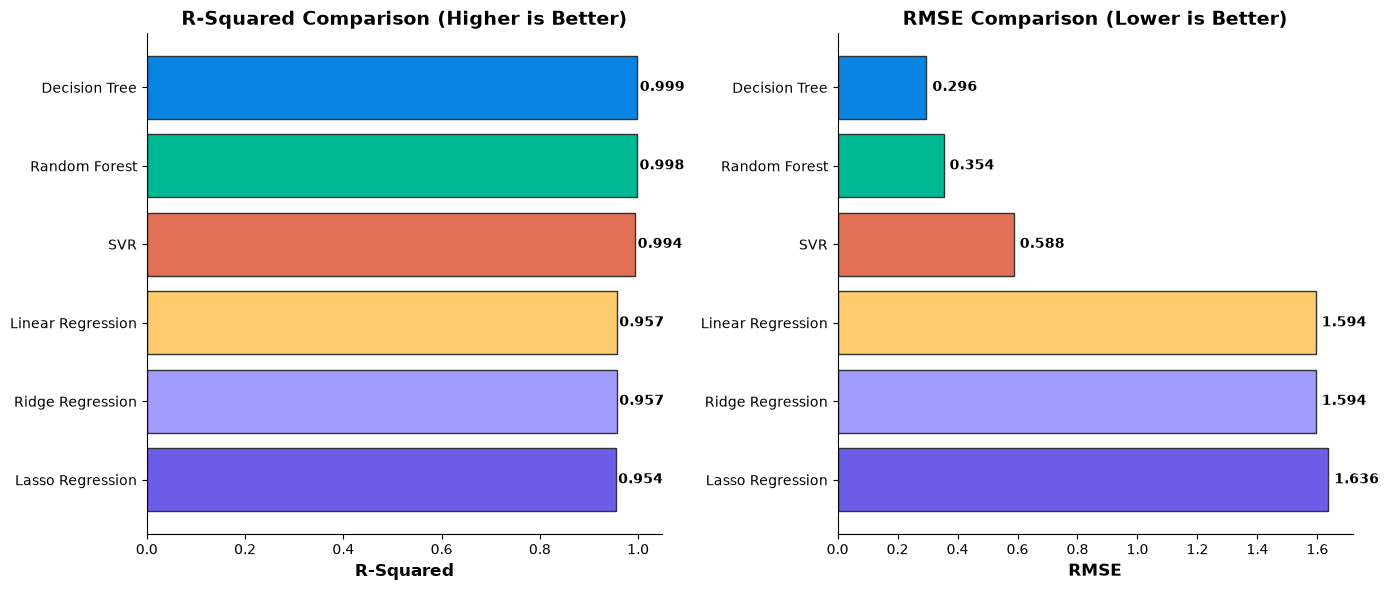

In [86]:
# Cell 40: Presentation-ready 1x2 horizontal bar chart comparing R2 and RMSE across all models
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ['#0984E3', '#00B894', '#E17055', '#FDCB6E', '#A29BFE', '#6C5CE7']

# Left subplot: R-Squared comparison
bars1 = axes[0].barh(comparison['Model'], comparison['R2'], color=colors[:len(comparison)], edgecolor='#2D3436')
axes[0].set_xlabel('R-Squared', fontsize=12, fontweight='bold')
axes[0].set_title('R-Squared Comparison (Higher is Better)', fontsize=14, fontweight='bold')
axes[0].invert_yaxis()
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
for bar, val in zip(bars1, comparison['R2']):
    axes[0].text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2,
                 f'{val:.3f}', va='center', fontsize=10, fontweight='bold')

# Right subplot: RMSE comparison
bars2 = axes[1].barh(comparison['Model'], comparison['RMSE'], color=colors[:len(comparison)], edgecolor='#2D3436')
axes[1].set_xlabel('RMSE', fontsize=12, fontweight='bold')
axes[1].set_title('RMSE Comparison (Lower is Better)', fontsize=14, fontweight='bold')
axes[1].invert_yaxis()
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
for bar, val in zip(bars2, comparison['RMSE']):
    axes[1].text(bar.get_width() + 0.02, bar.get_y() + bar.get_height() / 2,
                 f'{val:.3f}', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


In [87]:
# Cell 41: Save the best model and StandardScaler using joblib
champion_name = comparison.iloc[0]['Model']
model_map = {
    'Linear Regression': lr,
    'Ridge Regression': ridge,
    'Lasso Regression': lasso,
    'Decision Tree': dt,
    'Random Forest': rf,
    'SVR': svr
}
champion_model = model_map[champion_name]
joblib.dump(champion_model, 'air_quality_regressor.pkl')
joblib.dump(scaler, 'scaler.pkl')
print(f'Champion Model: {champion_name}')
print(f'Saved: air_quality_regressor.pkl')
print(f'Saved: scaler.pkl')

Champion Model: Decision Tree
Saved: air_quality_regressor.pkl
Saved: scaler.pkl
